![MOMENTUM · Hackatón de DRL · Entrenamiento](img/banner-train.jpg)

# **Código para el entrenamiento del agente**

Este cuaderno contiene el código necesario para entrenar un agente de [Stable Baselines 3](https://stable-baselines3.readthedocs.io/en/master/) en un entorno de la colección [`highway-env`](https://highway-env.farama.org/).

Primero, importamos las librerías necesarias:

In [1]:
import gymnasium as gym
import highway_env

from stable_baselines3 import A2C, DQN, PPO
from matplotlib import pyplot as plt
%matplotlib inline

Dada la componente aleatoria del entrenamiento, fijamos una semilla para el agente y el sampler de Optuna. Esto permite repetir el experimento bajo las mismas condiciones. Aún así, no garantiza resultados idénticos entre distintas versiones de las librerías o hardware.

In [2]:
import random

# Fijar la semilla
seed = 42
random.seed(seed)

## **1. Entorno de entrenamiento**

### **1.1 Selección del entorno**

**Dado que el entrenamiento de los agentes puede llevar bastante tiempo, se recomienda utilizar una variante simplificada llamada [`highway-fast-v0`](https://highway-env.farama.org/environments/highway/#faster-variant)**, que permite entrenar hasta 15 veces más rápido. No obstante, la evaluación será en el entorno no simplificado (`highway-v0`). Si bien es cierto que **un agente entrenado en `highway-fast-v0` puede generalizar y comportarse bien en `highway-v0`**, se recomienda usar el entorno simplificado para los entrenamientos más costosos (probar distintos algoritmos, ajustar hiperparámetros) y, una vez encontrada una buena configuración para el entrenamiento, entrenar el modelo definitivo en el entorno no simplificado, siempre y cuando sea posible por cuestiones de tiempo.

In [3]:
# Indica el entorno para el entrenamiento. Puedes cambiarlo por otro entorno de highway-env si lo deseas.
TRAIN_ENV_NAME = 'highway-fast-v0'

Dicho esto, visualizamos una instancia del entorno donde se va a entrenar el agente.

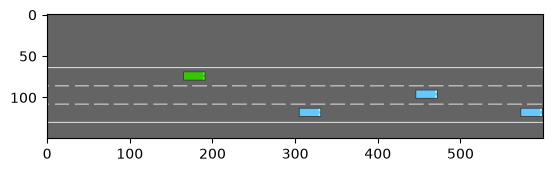

In [4]:
# Crear el entorno
env = gym.make(TRAIN_ENV_NAME, render_mode='rgb_array')

# Fijar una semilla para reproducibilidad
env.reset(seed=seed)

# Mostrar el estado inicial
plt.imshow(env.render())
plt.show()

A continuación, se muestran el espacio de observaciones y el espacio de acciones por defecto.

In [5]:
# Espacio de observaciones
print("Espacio de observaciones:", env.observation_space)

# Espacio de acciones
print("Espacio de acciones:", env.action_space)

# Se cierra el entorno de ejemplo
env.close()

Espacio de observaciones: Box(-inf, inf, (5, 5), float32)
Espacio de acciones: Discrete(5)


### **1.2 Configuración del entorno y wrappers**

En la función `make_env` se indica el entorno que vamos a utilizar para el entrenamiento. En el parámetro `config`, puedes modificar aspectos relativos a la dificultad del entorno (número de carriles, densidad de vehículos, etc.) así como la función de recompensa (penalización por colisión, bonificación por velocidad, etc.). Puedes consultar la configuración por defecto en la [documentación](https://highway-env.farama.org/environments/highway/). Ten en cuenta que el agente se evaluará con una configuración similar a la que hay por defecto, por lo que, si cambias la configuración, **no debes generar incompatibilidades**. Si tienes dudas sobre si algún cambio puede generar incompatibilidades, consulta a los mentores.

Una vez configurado el entorno, definimos los wrappers que consideremos necesarios y los llamamos en la función `aplicar_wrappers`. **Es importante tener en cuenta en qué orden se aplican, y mantener el mismo orden tanto en la evaluación como en la entrega final**. Recuerda que puedes consultar la documentación de los wrappers [aquí](https://gymnasium.farama.org/api/wrappers).

In [ ]:
# Define tus wrappers aqui (no usamos ninguno: solo hay que entregar best_model.zip)

# Aplica aqui todos los wrappers en el orden que consideres adecuado
from wrapper import aplicar_wrappers


# Configuracion de entrenamiento. Solo cambia el entrenamiento: la evaluacion usa highway-v0 por defecto.
# NO anadas aqui "observation" ni "action": romperia la compatibilidad con la evaluacion.
TRAIN_CONFIG = {
    "collision_reward": -2,      # Mejor resultado: -2 o -3 (por defecto -1)
    # "high_speed_reward": 0.4,  # NO subir: con 0.5-1.0 el agente choca mucho mas
    # "lanes_count": 4,          # highway-fast-v0 usa 3; la evaluacion, 4 (en pruebas)
    # "vehicles_count": 50,      # highway-fast-v0 usa 20; la evaluacion, 50 (en pruebas)
}


# Centraliza aqui la configuracion y los wrappers de todos los entornos
def make_env():
    new_env = gym.make(TRAIN_ENV_NAME, render_mode='rgb_array', config=TRAIN_CONFIG)
    new_env = aplicar_wrappers(new_env)
    return new_env

***

## **2. Entrenamiento de los agentes**

Una vez definido el entorno y los wrappers, especificaremos la configuración para el entrenamiento de los agentes: número de episodios de entrenamiento, evaluación, combinaciones de hiperparámetros a probar, etc.

**<span style="color:red">¡Atención!</span> El código de las siguientes celdas guarda el mejor agente resultante en un archivo dentro de la carpeta `agentes/<EXPERIMENT_NAME>`. Si ya existe una carpeta con el mismo nombre, el agente resultante de la última ejecución sobreescribirá al anterior, así que recuerda cambiar el valor de la variable `EXPERIMENT_NAME` y ejecutar la celda cada vez que modifiques la configuración del entrenamiento.**

In [6]:
EXPERIMENT_NAME = "PPO-all_wrap_hyper" # Nombre del experimento para guardar resultados

**Las variables definidas en la siguiente celda no se deben modificar**:

In [7]:
# Variables fijas que NO deben ser modificadas
N_JOBS = 1 # Numero de trabajos en paralelo para Optuna
TIMESTEPS_PER_EPISODE = 30 if TRAIN_ENV_NAME == "highway-fast-v0" else 40 # Numero de pasos por episodio
EVAL_EPISODES = 100 # Numero de episodios que dura cada evaluacion

**Las siguientes variables sí deben ser ajustadas**:

In [8]:
# Variables que SI pueden ser modificadas
TRAIN_EPISODES = 100 # PPO necesita mas experiencia que DQN (60k pasos ~ 4000 episodios cortos)
N_COMBINACIONES = 1 # Numero de combinaciones a explorar durante la optimizacion de hiperparametros
N_ENVS = 2 # Entornos en paralelo para PPO; subelo hasta el numero de nucleos de tu equipo

### **2.1 Definición de callbacks personalizados**

En la siguiente celda **definimos las clases** de los callbacks personalizados. Las **instancias** se crearán después, dentro de `objective`, para que cada entrenamiento tenga sus propios callbacks.

Para más información sobre callbacks personalizados, consulta [la documentación](https://stable-baselines3.readthedocs.io/en/master/guide/callbacks.html).

In [9]:
from stable_baselines3.common.callbacks import BaseCallback
from tqdm.std import tqdm

# Callback para mostrar una barra de progreso de texto durante el entrenamiento
class TextProgressBarCallback(BaseCallback):
    """
    Barra de progreso de texto para `learn()`. Hace lo mismo que `progress_bar=True`,
    que en VS Code necesita widgets de Jupyter y puede fallar.
    """
    def _on_training_start(self):
        self.bar = tqdm(total=self.locals["total_timesteps"], unit=" pasos")

    def _on_step(self):
        # Cada llamada es un paso de cada entorno en paralelo; SB3 puede pasarse un poco del total
        self.bar.update(min(self.training_env.num_envs, self.bar.total - self.bar.n))
        return True

    def _on_training_end(self):
        self.bar.close()


# Guarda la recompensa y la longitud de cada episodio de entrenamiento (sirve con varios entornos en paralelo)
class EpisodeLoggerCallback(BaseCallback):
    def _on_training_start(self):
        self.rewards, self.lengths = [], []

    def _on_step(self):
        for info in self.locals["infos"]:
            if "episode" in info:
                self.rewards.append(info["episode"]["r"])
                self.lengths.append(info["episode"]["l"])
        return True


# Define aqui las clases de tus callbacks personalizados.
# No olvides instanciarlos mas adelante en la funcion objective.

# class MiCallback(BaseCallback):
#     ...

### **2.2 Definición del entrenamiento y de los hiperparámetros**

Definimos la función `objective(trial)`, que Optuna ejecutará una vez por cada combinación de hiperparámetros. En ella seleccionamos los hiperparámetros, creamos el agente e instanciamos los callbacks definidos en la celda anterior. Ten en cuenta que esta celda solo define la función; el estudio de Optuna se ejecuta en la siguiente celda.


In [10]:
import optuna
import numpy as np
import shutil
from pathlib import Path
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.callbacks import CallbackList, StopTrainingOnMaxEpisodes

from src.core.callbacks import BestEpisodeCallback, InfoRewardEvalCallback

INFO_REWARD_KEYS = ("collision_reward", "right_lane_reward", "high_speed_reward", "on_road_reward")

# Semillas de validacion comunes a todos los trials, distintas de entrenamiento.
EVAL_SEEDS = [seed + 1000 + i for i in range(EVAL_EPISODES)]

# Diccionario para almacenar informacion sobre el mejor modelo entrenado
best_training_info = {}

# Definir la funcion para el/los entrenamiento/s
def objective(trial):

    # Hiperparametros. Los rangos con el mismo minimo y maximo fijan los valores probados.
    # Para buscar con Optuna, abre los rangos y sube N_COMBINACIONES.
    learning_rate = trial.suggest_float("learning_rate", 1e-7, 1e-3, log=True)
    gamma = trial.suggest_float("gamma", 0.9, 0.995)
    n_steps = trial.suggest_categorical("n_steps", [256,512,1024])        # pasos por entorno antes de cada actualizacion
    batch_size = 256
    n_epochs = 45
    ent_coef = 0.001       
    net_arch = [256,256]


    train_env = None
    eval_env = None
    trial_best_episode_path = Path(f"agentes/{EXPERIMENT_NAME}/.best_episode_trial_{trial.number}.zip")

    try:
        # PPO aprovecha varios entornos en paralelo (cada uno con su Monitor)
        train_env = make_vec_env(make_env, n_envs=N_ENVS, seed=seed)
        eval_env = DummyVecEnv([lambda: Monitor(make_env())])

        # Crear agente
        agent = PPO('MlpPolicy',
                    train_env, # No modificar
                    verbose=0, # No modificar
                    seed=seed, # No modificar

                    # Hiperparametros a optimizar
                    learning_rate=learning_rate,
                    gamma=gamma,
                    n_steps=n_steps,
                    batch_size=batch_size,
                    n_epochs=n_epochs,
                    ent_coef=ent_coef,
                    policy_kwargs=dict(net_arch=net_arch),
                    )


        # Instanciar los callbacks para este trial
        stop_training_callback = StopTrainingOnMaxEpisodes(max_episodes=TRAIN_EPISODES, verbose=1) # Limita el numero de episodios al indicado
        text_progress_bar_callback = TextProgressBarCallback() # Muestra una barra de progreso de texto durante el entrenamiento
        episode_logger = EpisodeLoggerCallback() # Recoge las recompensas de entrenamiento para la grafica
        best_episode_callback = BestEpisodeCallback(
            INFO_REWARD_KEYS,
            best_model_save_path=trial_best_episode_path,
        )

        info_reward_eval_callback = InfoRewardEvalCallback(
            eval_env,
            reward_keys=INFO_REWARD_KEYS,
            n_eval_episodes=10,
            eval_freq=40,
            best_model_save_path="./logs/",
            log_path="./logs/",
        )


        # Lista de callbacks. Incluye aqui los callbacks que quieras aplicar.
        callbacks = CallbackList([
            stop_training_callback,
            text_progress_bar_callback,
            episode_logger,
            best_episode_callback,
            # info_reward_eval_callback,
        ])


        # Entrenamiento del agente
        agent.learn(total_timesteps=TRAIN_EPISODES * TIMESTEPS_PER_EPISODE,
                    callback=callbacks,
                    )


        # Evaluacion de la politica del agente
        episode_rewards = []
        for eval_seed in EVAL_SEEDS:
            eval_env.seed(eval_seed)
            rewards, _ = evaluate_policy(
                agent,
                eval_env,
                n_eval_episodes=1,
                deterministic=True,
                return_episode_rewards=True,
            )
            episode_rewards.extend(rewards)
        mean_reward = float(np.mean(episode_rewards))

        # Si el agente es el mejor hasta ahora, se guarda el agente junto con informacion relevante
        completed_trials = trial.study.get_trials(states=(optuna.trial.TrialState.COMPLETE,))

        if not completed_trials or mean_reward > trial.study.best_value:
            agent.save(f"agentes/{EXPERIMENT_NAME}/best_model.zip")
            shutil.copy2(
                trial_best_episode_path,
                f"agentes/{EXPERIMENT_NAME}/best_episode_model.zip",
            )

            best_training_info.update({
                "rewards": np.asarray(episode_logger.rewards),
                "lengths": np.asarray(episode_logger.lengths),
                "info_rewards": {
                    key: np.asarray(values)
                    for key, values in best_episode_callback.episode_rewards.items()
                },
                "best_episode": best_episode_callback.best_episode,
                "best_episode_reward": best_episode_callback.best_reward,
                "best_episode_components": best_episode_callback.best_episode_components,
                "trial_number": trial.number,
                "validation_mean_reward": mean_reward,
            })

        # Se devuelve la recompensa media obtenida durante la evaluacion del agente entrenado
        return mean_reward

    finally:
        if eval_env is not None:
            eval_env.close()
        if train_env is not None:
            train_env.close()
        trial_best_episode_path.unlink(missing_ok=True)

### **2.3 Ejecución del entrenamiento**

Una vez definidos los callbacks y la función `objective`, creamos el estudio de Optuna y lanzamos los entrenamientos. Cada llamada a `objective` crea un agente y nuevas instancias de sus callbacks.

Si modificas una clase de callback, vuelve a ejecutar su celda antes de lanzar de nuevo el estudio. Si cambias los parámetros de sus instancias o la lista de callbacks, vuelve a ejecutar también la celda de `objective`.


In [11]:
import time

# Crear estudio de Optuna
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=seed, n_startup_trials=N_COMBINACIONES//3),
)

# Guardar la hora de inicio
start_time = time.time()

# Ejecutar entrenamiento
study.optimize(objective, n_trials=N_COMBINACIONES, n_jobs=N_JOBS)

# Guardar la hora de finalizacion
end_time = time.time()

[I 2026-10-27 15:29:32,500] A new study created in memory with name: no-name-45c122cb-9280-4fb3-81e0-29c421f136b4
  9%|▊         | 262/3000 [00:04<00:49, 55.14 pasos/s][W 2026-10-27 15:29:38,420] Trial 0 failed with parameters: {'learning_rate': 6.780863600693119e-06, 'gamma': 0.9005697323808026, 'n_steps': 1024} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/opt/venv/lib/python3.13/site-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "/tmp/ipykernel_85387/3188486298.py", line 91, in objective
    agent.learn(total_timesteps=TRAIN_EPISODES * TIMESTEPS_PER_EPISODE,
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                callback=callbacks,
                ^^^^^^^^^^^^^^^^^^^
                )
                ^
  File "/opt/venv/lib/python3.13/site-packages/stable_baselines3/ppo/ppo.py", line 311, in learn
    return super().learn(
           ~~~~~~~~~~~

KeyboardInterrupt: 

  9%|▉         | 266/3000 [00:19<00:49, 55.14 pasos/s]

 Una vez finalizado el entrenamiento, se muestra su duración, la mejor combinación de hiperparámetros explorada y la recompensa obtenida con dicha combinación. Esta información también se escribe en el archivo `agentes/<EXPERIMENT_NAME>/info_train.txt`.

In [ ]:
# Mostrar informacion sobre el entrenamiento
print(f"El entrenamiento {EXPERIMENT_NAME} ha durado {end_time - start_time:.2f} segundos.")
print(f"Mejor recompensa obtenida: {study.best_value:.2f}")
print(f"Se han probado {N_COMBINACIONES} combinaciones de hiperparametros.")
print(f"Mejores hiperparametros:\n{study.best_params}")


# Escribir informacion util sobre el entrenamiento en un archivo de texto
with open(f"./agentes/{EXPERIMENT_NAME}/info_train.txt", "w") as f:
    f.write(f"Informacion sobre el experimento {EXPERIMENT_NAME}\n")
    f.write(f"\n - Duracion: {end_time - start_time:.2f} segundos.")
    f.write(f"\n - La mejor recompensa obtenida ha sido: {study.best_value:.2f}")
    f.write(f"\n - Se han probado {N_COMBINACIONES} combinaciones de hiperparametros.")
    f.write(f"\n - Los hiperparametros del mejor modelo encontrado son:\n\t{study.best_params}")


A continuación, graficamos la recompensa total y cada componente de recompensa acumulada durante el entrenamiento del mejor trial. Cada componente tiene su propia gráfica por episodio, junto con una media móvil de 10 episodios. Las gráficas se guardan en `agentes/<EXPERIMENT_NAME>/reward_evolution.png` y `agentes/<EXPERIMENT_NAME>/training_info_reward_plots/`.


In [ ]:
# Evolucion de las recompensas de entrenamiento del mejor trial.
WINDOW = 10  # Numero de episodios para la media movil
training_rewards = best_training_info["rewards"]
training_episodes = np.arange(1, len(training_rewards) + 1)

# Grafica de la recompensa total por episodio.
rolling_mean = np.array([
    training_rewards[max(0, i - WINDOW + 1):i + 1].mean()
    for i in range(len(training_rewards))
])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(training_episodes, training_rewards, alpha=0.35, label="Recompensa total por episodio")
ax.plot(training_episodes, rolling_mean, label=f"Media movil ({WINDOW} episodios)")
if best_training_info.get("best_episode") is not None:
    ax.axvline(best_training_info["best_episode"], color="red", alpha=0.5, label="Mejor episodio")
ax.set_xlabel("Episodio de entrenamiento")
ax.set_ylabel("Recompensa total")
ax.set_title(f"Recompensa total: trial {best_training_info['trial_number']}")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(f"agentes/{EXPERIMENT_NAME}/reward_evolution.png")
plt.show()
plt.close(fig)

# Graficas separadas de cada componente acumulada durante los episodios de entrenamiento.
from src.core.evaluation import plot_info_reward_episodes

if "info_rewards" not in best_training_info:
    raise RuntimeError("Rerun the training after adding InfoRewardTrainingCallback to collect component rewards.")

plot_info_reward_episodes(
    best_training_info["info_rewards"],
    save_dir=f"agentes/{EXPERIMENT_NAME}/training_info_reward_plots",
    rolling_window=WINDOW,
    best_episode=best_training_info.get("best_episode"),
)


Estos resultados se obtienen durante el entrenamiento. Sin embargo, **para medir el desempeño del mejor agente de forma justa, se debe evaluar en un entorno diferente**. Para ello, utiliza el **[notebook de test](test.ipynb)**. En él, encontrarás el código necesario para evaluar un agente ya entrenado, además de la obtención de métricas que facilitan el análisis de la política aprendida.